In [ ]:
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit import transpile
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from qiskit_aer.noise import (NoiseModel, QuantumError, ReadoutError,
    pauli_error, depolarizing_error, thermal_relaxation_error)
#import bitstring
from qiskit_aer import AerSimulator
# import classes as c
import sys
sys.path.insert(0, "/home/dustinseboldt/Desktop/iqpe")
from HPC.Upload.pyfiles import classes as c

plt.rcParams.update({"font.family": "serif", "text.usetex": True,
                     "font.size": 16, "axes.labelsize": 18, "axes.titlesize": 18,
                     "legend.fontsize": 14, "xtick.labelsize": 15, "ytick.labelsize": 15,
                     "axes.linewidth": 1.2,
                     "xtick.major.width": 1.2, "ytick.major.width": 1.2,
                     "xtick.minor.width": 0.8, "ytick.minor.width": 0.8,
                     "xtick.major.size": 6, "ytick.major.size": 6,
                     "xtick.minor.size": 3.5, "ytick.minor.size": 3.5})

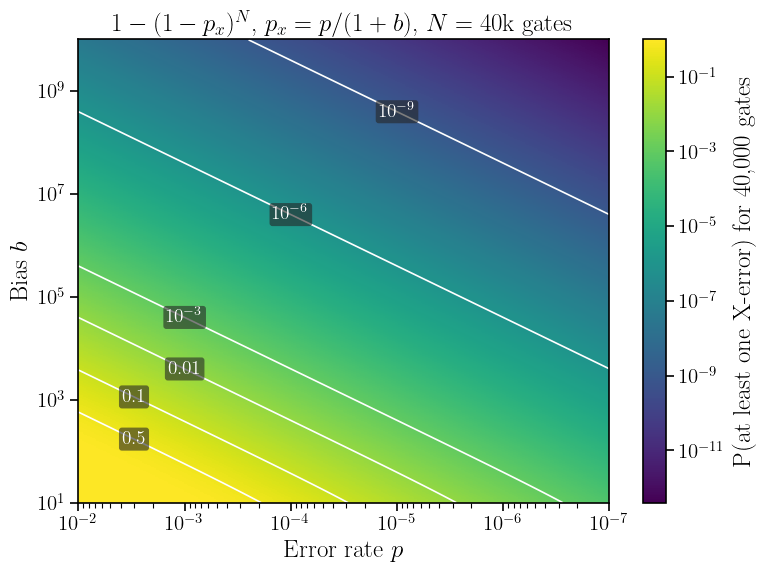

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

gates = 40_000

# Axes: error rate p (log, 1e-2 -> 1e-7) and bias b (log, 1e1 -> 1e10)
p = np.logspace(-2, -7, 400)
bias = np.logspace(1, 10, 400)
P, B = np.meshgrid(p, bias)
p_x = P / (1 + B)

# Probability of NO error:            (1 - p_x)**gates
# Probability of AT LEAST ONE error:  1 - (1 - p_x)**gates
# log1p/expm1 keep precision when p_x is tiny (down to ~1e-17)
p_no_err = np.exp(gates * np.log1p(-p_x))
p_err = -np.expm1(gates * np.log1p(-p_x))

fig, ax = plt.subplots(figsize=(8, 6))
mesh = ax.pcolormesh(P, B, p_err, shading="auto", cmap="viridis",
                     norm=LogNorm(vmin=p_err.min(), vmax=1), rasterized=True)
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label(f"P(at least one X-error) for {gates:,} gates")
cbar.ax.tick_params(labelsize=15, width=1.2, length=6)
cbar.outline.set_linewidth(1.2)

# Contour lines for a few reference probabilities
# (contour on log10 values so the lines are evenly resolved across decades)
levels = [1e-9, 1e-6, 1e-3, 1e-2, 0.1, 0.5]
cs = ax.contour(P, B, np.log10(p_err), levels=np.log10(levels),
                colors="white", linewidths=1.2, linestyles="solid")

def fmt(v):
    lvl = 10**v
    return f"${lvl:g}$" if lvl >= 0.01 else rf"$10^{{{round(v)}}}$"

# Place labels by hand so they don't pile up at the edges:
# for small values P_err ~ N p/(1+b), so the label for level L sits near b = N p / L
label_p = {0.5: 3e-3, 0.1: 3e-3, 1e-2: 1e-3, 1e-3: 1e-3, 1e-6: 1e-4, 1e-9: 1e-5}
manual = [(pp, gates * pp / -np.log1p(-L)) for L, pp in label_p.items()]
labels = ax.clabel(cs, fmt=fmt, fontsize=14, manual=manual, inline=False)
# inline=True cuts the lines incorrectly on log axes, so give labels a small backdrop instead
for t in labels:
    t.set_rotation(0)
    t.set_bbox(dict(boxstyle="round,pad=0.15", fc="0.15", ec="none", alpha=0.6))

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-2, 1e-7)   # p decreasing from left to right
ax.set_xlabel("Error rate $p$")
ax.set_ylabel("Bias $b$")
ax.set_title(r"$1-(1-p_x)^{N}$,  $p_x = p/(1+b)$,  $N = 40$k gates")

plt.tight_layout()
plt.savefig("Figures for Masterthesis/1.pdf", dpi=300)
plt.show()

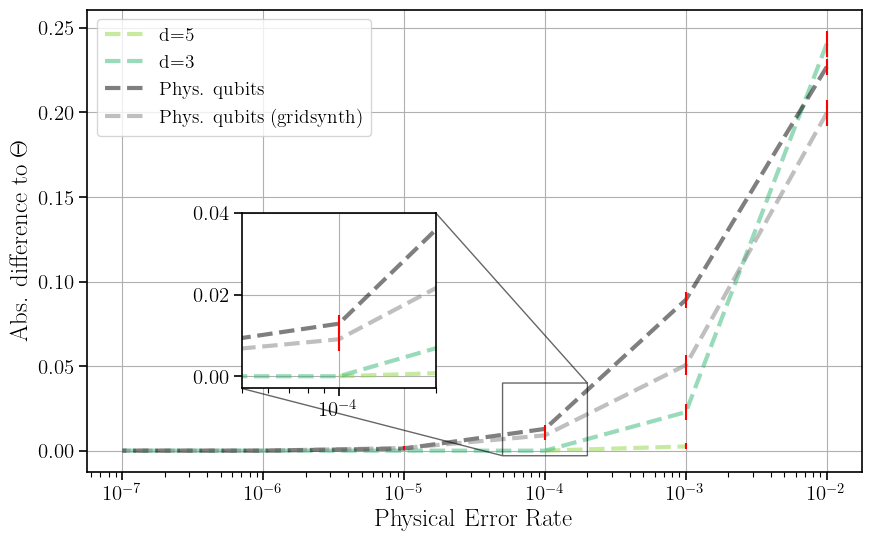

In [21]:
# Phaseflipcode, new Shor QEC, U=R_Z, nur ein Winkel iQPE

p4, y_qec4, err_qec4 = np.loadtxt("HPC/text/d5_rz_short_newshorqec_crossover_angle0.txt", delimiter = ",")
p5, y_qec5, err_qec5 = np.loadtxt("HPC/text/d3_rz_short_newshorqec_crossover_angle0.txt", delimiter = ",")
p6, y6, err6 = np.loadtxt("HPC/text/physicalq_rz_crossover_angle0.txt", delimiter =",")
p7, y7, err7 = np.loadtxt("HPC/text/physicalq_steane_crossover_angle0.txt", delimiter =",") 

fig, ax1 = plt.subplots(figsize=(10,6))

colors = plt.cm.viridis(np.linspace(0, 1, 7))

def plot_curves(ax):
    ax.plot(p4, y_qec4, label="d=5", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[5], linewidth=3)
    ax.errorbar(p4, y_qec4, yerr=err_qec4, ecolor="red", linestyle="")

    ax.plot(p5, y_qec5, label="d=3", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[4], linewidth=3)
    ax.errorbar(p5, y_qec5, yerr=err_qec5, ecolor="red", linestyle="")

    ax.plot(p6,y6, label="Phys. qubits", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = "black", linewidth=3)
    ax.errorbar(p6, y6, yerr=err6, ecolor="red", linestyle="")

    ax.plot(p7,y7, label="Phys. qubits (gridsynth)", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = "grey", linewidth=3)
    ax.errorbar(p7, y7, yerr=err7, ecolor="red", linestyle="")


plot_curves(ax1)

# ax1.set_title(r"Phaseflip, 3 Iter., $U=R_Z(\Theta)$, b=-1e99 ($\varphi = 0.125$)")
ax1.set_xlabel("Physical Error Rate")
ax1.set_ylabel(r"Abs. difference to $\Theta$")
ax1.tick_params(axis='both', which='major')
ax1.grid()
ax1.legend(loc="upper left")
ax1.set_xscale("log")#, ax1.set_yscale("log")

############################################################################################################################
# Zoom-Fenster um p = 1e-4 (alle drei Kurven)
p_zoom = 1e-4
axins = ax1.inset_axes([0.2, 0.18, 0.25, 0.38])            # [x0, y0, Breite, Hoehe] in Achsen-Koordinaten
plot_curves(axins)
axins.set_xscale("log")
axins.set_xlim(p_zoom/2, p_zoom*2)
axins.set_ylim(-0.003, 0.04)
axins.set_xticks([p_zoom])
axins.tick_params(axis='both', which='major')
axins.tick_params(axis='x', which='minor', labelbottom=False)
axins.grid()
ax1.indicate_inset_zoom(axins, edgecolor="black", alpha=0.6)
############################################################################################################################
# plt.tight_layout()
plt.savefig("Figures for Masterthesis/2.pdf", bbox_inches="tight" ,dpi=300)
plt.show()

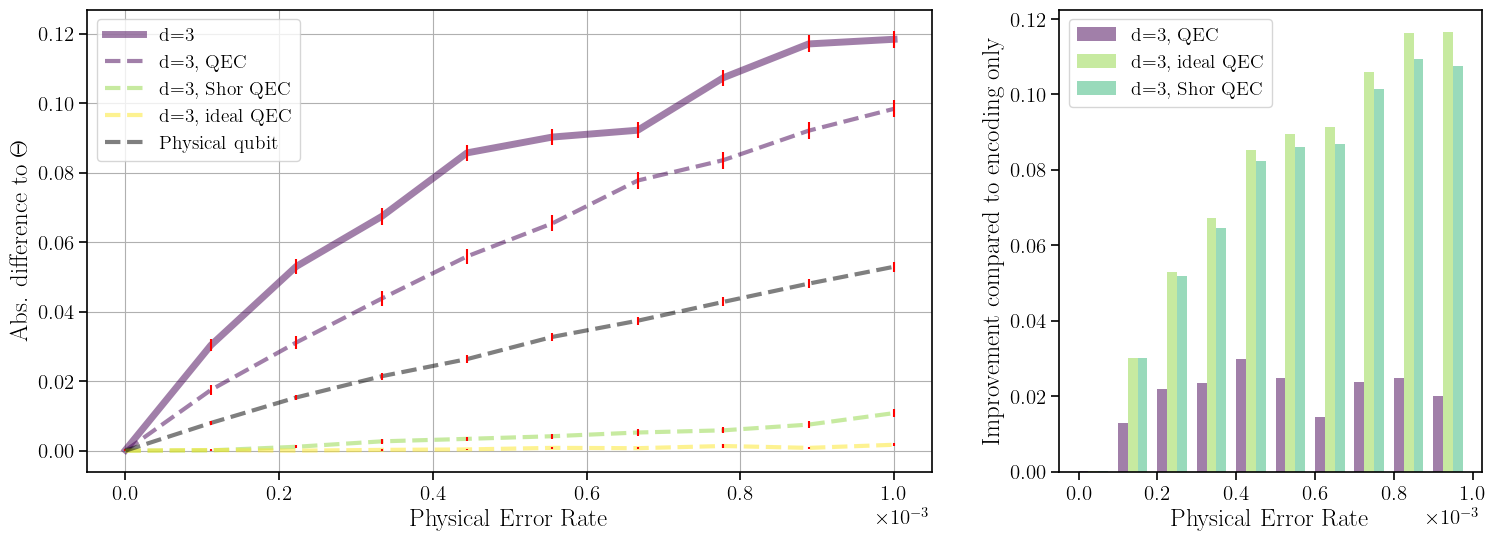

In [9]:
# Phaseflipcode mit bias preserving [H,X,Z,CX,CCX] Gateset, improved mit beamsearch, aka etwa 20% weniger CX, RZ und nur einer Unitary U, nicht 2xsqrt(U)!!!
shots = 400

p1, y1, y_qec1, err1, err_qec1 = np.loadtxt("HPC/text/d3_rz_short.txt", delimiter = ",")
p2, y2, err2 = np.loadtxt("HPC/text/d5_rz_short_noqec.txt", delimiter = ",")
p3, y_qec3, err_qec3 = np.loadtxt("HPC/text/d3_rz_short_newshorqec.txt", delimiter = ",")
p4, y_qec4, err_qec4 = np.loadtxt("HPC/text/d3_rz_short_newqecideal.txt", delimiter = ",")                
p5, y_qec5, err_qec5 = np.loadtxt("HPC/text/d3_rz_short_shorqec.txt", delimiter = ",")
p6, y6, err6 = np.loadtxt("HPC/text/physicalq_rz.txt", delimiter =",")

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(18,6), gridspec_kw={"width_ratios": [2, 1]})

# try:
colors = plt.cm.viridis(np.linspace(0, 1, 7))
# except TypeError:
#     pass

ax1.plot(p1,y1, label="d=3", marker = "", linestyle = "-", markersize = 20, alpha = 0.5, color = colors[0], linewidth=5)
ax1.errorbar(p1, y1, yerr=err1, ecolor="red", linestyle="")

ax1.plot(p1, y_qec1, label="d=3, QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[0], linewidth=3)
ax1.errorbar(p1, y_qec1, yerr=err_qec1, ecolor="red", linestyle="")

ax1.plot(p3, y_qec3, label="d=3, Shor QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[5], linewidth=3)
ax1.errorbar(p3, y_qec3, yerr=err_qec3, ecolor="red", linestyle="")

ax1.plot(p4, y_qec4, label="d=3, ideal QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[6], linewidth=3)
ax1.errorbar(p4, y_qec4, yerr=err_qec4, ecolor="red", linestyle="")

ax1.plot(p6,y6, label="Physical qubit", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = "black", linewidth=3)
ax1.errorbar(p6, y6, yerr=err6, ecolor="red", linestyle="")


# ax1.set_title(r"Phaseflip, 3 Iter., $U=R_Z(\Theta)$, b=-1e99")
ax1.set_xlabel("Physical Error Rate")
ax1.set_ylabel(r"Abs. difference to $\Theta$")
ax1.tick_params(axis='both', which='major')
ax1.grid()
ax1.legend()
############################################################################################################################
x_hist = np.asarray(p1)

qec_hist = -(np.asarray(y_qec1) - np.asarray(y1))
idealqec_hist = -(np.asarray(y_qec4) - np.asarray(y1))
shorqec_hist = -(np.asarray(y_qec3) - np.asarray(y1))


# Use the same bin edges for all histograms
bins = np.histogram_bin_edges(x_hist, bins=10)
bin_width = bins[1] - bins[0]

# Calculate weighted histogram values
qec_counts, _ = np.histogram(x_hist, bins=bins, weights=qec_hist)
idealqec_counts, _ = np.histogram(x_hist, bins=bins, weights=idealqec_hist)
shorqec_counts, _ = np.histogram(x_hist, bins=bins, weights=shorqec_hist)


# Four bars side-by-side within each bin
bar_width = bin_width / 4
x = bins[:-1]

ax2.bar(
    x,
    qec_counts,
    width=bar_width,
    align="edge",
    alpha=0.5,
    color=colors[0],
    label="d=3, QEC"
)

ax2.bar(
    x + bar_width,
    idealqec_counts,
    width=bar_width,
    align="edge",
    alpha=0.5,
    color=colors[5],
    label="d=3, ideal QEC"
)

ax2.bar(
    x + 2 * bar_width,
    shorqec_counts,
    width=bar_width,
    align="edge",
    alpha=0.5,
    color=colors[4],
    label="d=3, Shor QEC"
)


ax2.legend()
ax2.tick_params(axis='both', which='major')
ax2.set_xlabel("Physical Error Rate")
ax2.set_ylabel(r"Improvement compared to encoding only")
ax1.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
ax2.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))

############################################################################################################################
#plt.tight_layout()
plt.savefig("Figures for Masterthesis/3.pdf", bbox_inches="tight" ,dpi=300)
plt.show()

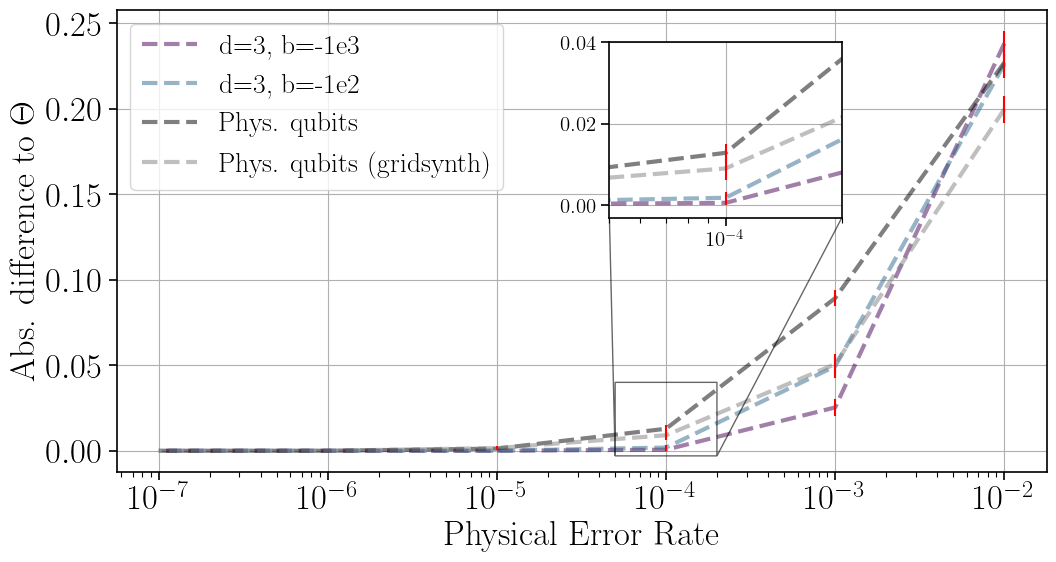

In [23]:
shots = 400

p1, y_qec1, err_qec1 = np.loadtxt("HPC/text/d3_rz_short_newshorqec_1e3_angle0.txt", delimiter = ",")
p2, y_qec2, err_qec2 = np.loadtxt("HPC/text/d3_rz_short_newshorqec_1e2_angle0.txt", delimiter = ",")
# p3, y_qec3, err_qec3 = np.loadtxt("HPC/text/d3_rz_short_crossover_shorqec.txt", delimiter = ",")
p4, y_qec4, err_qec4 = np.loadtxt("HPC/text/d5_rz_short_newshorqec_crossover_angle0.txt", delimiter = ",")                
p5, y_qec5, err_qec5 = np.loadtxt("HPC/text/d3_rz_short_newshorqec_crossover_angle0.txt", delimiter = ",")
p6, y6, err6 = np.loadtxt("HPC/text/physicalq_rz_crossover_angle0.txt", delimiter =",") 
p7, y7, err7 = np.loadtxt("HPC/text/physicalq_steane_crossover_angle0.txt", delimiter =",") 

fig, ax1 = plt.subplots(figsize=(12,6))

colors = plt.cm.viridis(np.linspace(0, 1, 7))

def plot_curves(ax1):
    ax1.plot(p1, y_qec1, label=r"d=3, b=-1e3", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[0], linewidth=3)
    ax1.errorbar(p1, y_qec1, yerr=err_qec1, ecolor="red", linestyle="")

    ax1.plot(p2, y_qec2, label=r"d=3, b=-1e2", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[2], linewidth=3)
    ax1.errorbar(p2, y_qec2, yerr=err_qec2, ecolor="red", linestyle="")

    # ax1.plot(p3, y_qec3, label="d=3, Shor QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[5], linewidth=3)
    # ax1.errorbar(p3, y_qec3, yerr=err_qec3, ecolor="red", linestyle="")

    ax1.plot(p6,y6, label="Phys. qubits", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = "black", linewidth=3)
    ax1.errorbar(p6, y6, yerr=err6, ecolor="red", linestyle="")

    ax1.plot(p7,y7, label="Phys. qubits (gridsynth)", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = "grey", linewidth=3)
    ax1.errorbar(p7, y7, yerr=err7, ecolor="red", linestyle="")


plot_curves(ax1)

# ax1.set_title(r"Phaseflip, 3 Iter., $U=R_Z(\Theta)$, b=-1e99 ($\varphi = 0.125$)", fontsize=20)
ax1.set_xlabel("Physical Error Rate", fontsize=25)
ax1.set_ylabel(r"Abs. difference to $\Theta$", fontsize=25)
ax1.tick_params(axis='both', which='major', labelsize=25)
ax1.grid()
ax1.legend(fontsize=20, loc="upper left")
ax1.set_xscale("log")#, ax1.set_yscale("log")

############################################################################################################################
# Zoom-Fenster um p = 1e-4 (alle drei Kurven)
p_zoom = 1e-4
axins = ax1.inset_axes([0.53, 0.55, 0.25, 0.38])            # [x0, y0, Breite, Hoehe] in Achsen-Koordinaten
plot_curves(axins)
axins.set_xscale("log")
axins.set_xlim(p_zoom/2, p_zoom*2)
axins.set_ylim(-0.003, 0.04)
axins.set_xticks([p_zoom])
axins.tick_params(axis='both', which='major', labelsize=15)
axins.tick_params(axis='x', which='minor', labelbottom=False)
axins.grid()
ax1.indicate_inset_zoom(axins, edgecolor="black", alpha=0.6)
############################################################################################################################
# plt.tight_layout()
plt.savefig("Figures for Masterthesis/4.pdf", bbox_inches="tight" ,dpi=300)
plt.show()